# Adım 2 (v4): CNN Eğitimi, eğitim tarifi iyileştirildi

**Neden v4?** Lezyon bazlı ayrım kullanan bir 2026 karşılaştırma çalışmasında EfficientNet-B0 testte ~0,74 dengeli doğruluk ve ~0,88 doğruluk almış; bizim v3 testte 0,658 ve 0,804'te kaldı. Makro AUC ise neredeyse aynı (0,960'a karşı 0,969). Yani model sınıfları ayırt edebiliyor, ama eğitim tarifimiz geliştirilebilir.

**v3'e göre değişenler:**
1. **Ön işleme tutarlılığı:** Görüntüler küçültüldükten sonra en yakın tamsayıya **yuvarlanır** (v3'te kesiliyordu). Adım 3 ve sonraki bütün adımlar aynı `onisle` fonksiyonunu kullanacak.
2. **Daha güçlü veri çoğaltma:** 360° döndürme (dermoskopide yön anlamsız), kaydırma, daha geniş yakınlaştırma, parlaklık ve kontrast değişimi. v3'te 10. turdan sonra ezber başlamıştı.
3. **Öğrenme oranı planı:** 1 tur ısınma, ardından kosinüs biçiminde yavaşça azalan öğrenme oranı (40 tur, sabır 8). Sabit öğrenme oranından daha kararlı ve genellikle daha iyi sonuç verir.
4. **Test anında çoğaltma (TTA):** Her görüntü 8 farklı yönde (döndürme ve aynalama) tahmin edilir, sonuçlar ortalanır.
5. **Klinik kısıtlı karar ayarı (τ):** Dengeli doğruluğu en yükselten τ'nun yanında, "nevüs duyarlılığı en az 0,80 olsun" kısıtıyla seçilen τ da raporlanır.
6. **İsteğe bağlı ConvNeXt-Tiny:** `MODEL_TIPI = 'ConvNeXtTiny'` (karşılaştırma çalışmasında en iyilerden biri; daha yavaş).

**Model seçim kuralı (sonucu görmeden önce yazıldı):** v3 ile v4 arasında seçim **yalnızca doğrulama kümesine** göre yapılır: en yüksek ayarsız dengeli doğruluk; fark 0,01'den küçükse doğrulama kaybı (NLL) düşük olan. Test kümesine bakılmaz. 12. hücre bu kuralı otomatik uygular.

**Başlamadan önce:** *Çalışma zamanı → GPU* (mümkünse A100 veya L4). B0 ile yaklaşık 15-25 dakika.

## 1. Ortam: GPU, Drive ve ayarlar

In [1]:
import os, json, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

from google.colab import drive
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpular = tf.config.list_physical_devices('GPU')
print('GPU:', gpular if gpular else 'YOK! Çalışma zamanı türünü GPU yapın.')

# ---- Ayarlar ----
MODEL_TIPI  = 'B0'          # 'B0' (önerilen), 'B3' ya da 'ConvNeXtTiny'
SURUM       = 'v4'
MODEL_ADI   = f'cnn_{MODEL_TIPI.lower()}_{SURUM}'   # kaydedilecek dosya adı
IMG         = {'B0': 224, 'B3': 300, 'ConvNeXtTiny': 224}[MODEL_TIPI]   # modelin giriş boyutu
BATCH       = 32
EPOCH_BAS   = 5             # 1. aşama: yalnızca sınıflandırma katmanı
EPOCH_INCE  = 40            # 2. aşama: ince ayar (erken durdurma ile kısalabilir)
LR_BAS      = 1e-3
LR_INCE     = 1e-4
ACILACAK    = 'hepsi'       # 2. aşamada eğitime açılacak katmanlar: 'hepsi' ya da bir sayı (ör. 60)
SABIR       = 8             # seçim ölçütü bu kadar tur iyileşmezse dur
SECIM_OLCUTU = 'val_loss'   # en iyi tur neye göre seçilsin: 'val_loss' (önerilen) ya da 'dengeli'
AGIRLIK_AZALMA = 1e-4       # AdamW ağırlık azaltma (ezberi azaltır)
AGIRLIK_TIPI = 'karekok'    # 'karekok' (yumuşak) ya da 'dengeli' (v1'deki sert ağırlık)
NEVUS_ALT_SINIR = 0.80      # klinik kısıtlı τ: nevüs duyarlılığı en az bu kadar olsun
print('Model:', MODEL_ADI, '| Giriş boyutu:', IMG, '| Ağırlık:', AGIRLIK_TIPI, '| Seçim:', SECIM_OLCUTU)
TOHUM       = 42
AGIRLIKLAR  = 'imagenet'

keras.utils.set_random_seed(TOHUM)
if gpular:
    keras.mixed_precision.set_global_policy('mixed_float16')  # GPU'da yaklaşık 2 kat hız

SINIFLAR = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']   # sabit sıra, sonraki adımlar da bunu kullanacak
SINIF_ADI = {'akiec': 'Aktinik keratoz', 'bcc': 'Bazal hücreli karsinom', 'bkl': 'Benign keratoz',
             'df': 'Dermatofibrom', 'mel': 'Melanom', 'nv': 'Melanositik nevüs (ben)', 'vasc': 'Vasküler lezyon'}
os.makedirs(f'{PROJE}/models', exist_ok=True)
os.makedirs(f'{PROJE}/results', exist_ok=True)

Mounted at /content/drive
TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model: cnn_b0_v4 | Giriş boyutu: 224 | Ağırlık: karekok | Seçim: val_loss


## 2. Görüntüleri Drive'daki zip'ten aç ve ayrımı yükle
Kaggle'dan tekrar indirmiyoruz; Adım 1'de Drive'a kaydedilen zip'i Colab'ın hızlı diskine açıyoruz.

In [2]:
ZIP = f'{PROJE}/data/skin-cancer-mnist-ham10000.zip'
if not os.path.exists('/content/ham'):
    !unzip -q -n "{ZIP}" -d /content/ham
GORUNTU_KOKU = '/content/ham'

yollar = {}
for p in glob.glob(f'{GORUNTU_KOKU}/**/*.jpg', recursive=True):
    yollar.setdefault(os.path.splitext(os.path.basename(p))[0], p)

meta = pd.read_csv(f'{PROJE}/splits/ham10000_split.csv')
meta['path'] = meta['image_id'].map(yollar)
meta['y'] = meta['dx'].map({s: i for i, s in enumerate(SINIFLAR)})
assert meta['path'].notna().all(), 'Bazı görüntüler bulunamadı!'
assert meta.groupby('lesion_id')['split'].nunique().max() == 1, 'Ayrımda sızıntı var!'

egitim    = meta[meta['split'] == 'egitim'].reset_index(drop=True)
dogrulama = meta[meta['split'] == 'dogrulama'].reset_index(drop=True)
print('Eğitim:', len(egitim), '| Doğrulama:', len(dogrulama), '| Test (bu adımda kullanılmıyor):', (meta['split'] == 'test').sum())

Eğitim: 7054 | Doğrulama: 1464 | Test (bu adımda kullanılmıyor): 1497


## 3. Veri hattı ve veri çoğaltma
- **Ön işleme (`onisle`):** Görüntü 224×224'e küçültülür ve en yakın tamsayıya yuvarlanır. Sonraki bütün adımlar bu fonksiyonu kullanacak.
- Görüntüler belleğe alınır; her turda diskten okunmaz.
- **Veri çoğaltma yalnızca eğitimde:** çevirme, 360° döndürme, ±%20 yakınlaştırma, ±%10 kaydırma, kontrast ve parlaklık değişimi. Kopyalar kaydedilmez; model her turda farklı varyasyonlar görür.

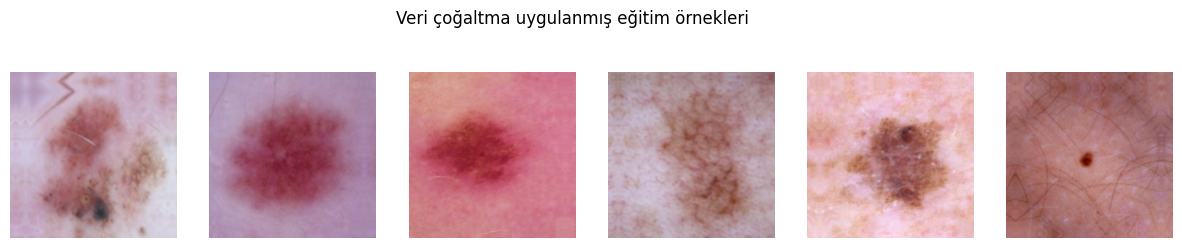

In [3]:
def onisle(goruntu):
    """Bütün adımlarda aynı ön işleme: IMG×IMG'ye küçült, en yakın tamsayıya yuvarla (uint8)."""
    goruntu = tf.image.resize(goruntu, (IMG, IMG))
    return tf.cast(tf.round(tf.clip_by_value(goruntu, 0, 255)), tf.uint8)

def oku(yol, y):
    return onisle(tf.io.decode_jpeg(tf.io.read_file(yol), channels=3)), y

cogaltma = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.5, fill_mode='reflect'),               # 360°: dermoskopide yön anlamsız
    layers.RandomZoom((-0.2, 0.2), fill_mode='reflect'),
    layers.RandomTranslation(0.1, 0.1, fill_mode='reflect'),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.15, value_range=(0, 255)),
], name='veri_cogaltma')

def veri_hatti(df, egitim_mi):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df['y'].values))
    ds = ds.map(oku, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if egitim_mi:
        ds = ds.shuffle(len(df), seed=TOHUM, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if egitim_mi:
        ds = ds.map(lambda x, y: (cogaltma(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

egitim_ds    = veri_hatti(egitim, True)
dogrulama_ds = veri_hatti(dogrulama, False)
y_dogrulama  = dogrulama['y'].values

# Çoğaltılmış birkaç eğitim görüntüsüne göz at
ornek, _ = next(iter(egitim_ds))
fig, eksen = plt.subplots(1, 6, figsize=(15, 3))
for i in range(6):
    eksen[i].imshow(np.clip(ornek[i].numpy(), 0, 255).astype('uint8')); eksen[i].axis('off')
plt.suptitle('Veri çoğaltma uygulanmış eğitim örnekleri'); plt.show()

## 4. Sınıf ağırlıkları
Nadir sınıflarda yapılan hatalar daha çok cezalandırılır.
- **dengeli:** ağırlık = toplam / (sınıf sayısı × o sınıfın örnek sayısı). En nadir sınıf, nevüsün ~63 katı ağırlık alır. v1'de bu kullanıldı ve model nadir sınıfları gereğinden fazla tahmin etti.
- **karekok:** dengeli ağırlıkların karekökü. Fark ~8 kata iner; nadir sınıflar yine öne çıkar ama model dengesini kaybetmez.

In [4]:
from sklearn.utils.class_weight import compute_class_weight
agirlik = compute_class_weight('balanced', classes=np.arange(len(SINIFLAR)), y=egitim['y'].values)
if AGIRLIK_TIPI == 'karekok':
    agirlik = np.sqrt(agirlik)
    agirlik = agirlik / (agirlik * np.bincount(egitim['y'], minlength=len(SINIFLAR))).sum() * len(egitim)  # ortalama ağırlık 1 olsun
SINIF_AGIRLIGI = {i: float(a) for i, a in enumerate(agirlik)}
print(pd.DataFrame({'sinif': [SINIF_ADI[s] for s in SINIFLAR],
                    'egitim_ornegi': np.bincount(egitim['y'], minlength=len(SINIFLAR)),
                    'agirlik': agirlik.round(2)}).to_string(index=False))
print(f'En büyük / en küçük ağırlık oranı: {agirlik.max() / agirlik.min():.1f}')

                  sinif  egitim_ornegi  agirlik
        Aktinik keratoz            233     2.60
 Bazal hücreli karsinom            365     2.08
         Benign keratoz            775     1.43
          Dermatofibrom             76     4.56
                Melanom            777     1.43
Melanositik nevüs (ben)           4730     0.58
        Vasküler lezyon             98     4.01
En büyük / en küçük ağırlık oranı: 7.9


## 5. Modeli kur
- **EfficientNet** (B0/B3) ya da **ConvNeXt-Tiny**, ImageNet'teki milyonlarca görüntüyle önceden eğitilmiş olarak gelir (transfer öğrenme). Kendi ön işlemesini içerir; 0-255 aralığındaki görüntüyü doğrudan alır.
- Üstüne bir **Dropout** ve **7 sınıflı çıkış katmanı** ekliyoruz.
- Çıkış katmanı olasılık yerine **logit** (ham skor) verir. Adım 3'teki kalibrasyon (sıcaklık ölçekleme) logitlere ihtiyaç duyar; olasılığı softmax ile biz hesaplarız.
- Ara katmanlar düz bir yapıda tutulur; böylece Adım 3'te ısı haritası (Grad-CAM) ve Adım 4'te benzer vaka arşivi için içlerine erişebiliriz.

In [5]:
girdi = keras.Input(shape=(IMG, IMG, 3), name='goruntu')
if MODEL_TIPI == 'ConvNeXtTiny':
    govde = keras.applications.ConvNeXtTiny(include_top=False, weights=AGIRLIKLAR, input_tensor=girdi,
                                            include_preprocessing=True)
else:
    GOVDE = {'B0': keras.applications.EfficientNetB0, 'B3': keras.applications.EfficientNetB3}[MODEL_TIPI]
    govde = GOVDE(include_top=False, weights=AGIRLIKLAR, input_tensor=girdi)
CAM_KATMANI = govde.layers[-1].name   # Grad-CAM için son evrişim katmanının adı (Adım 3 kullanacak)
x = layers.GlobalAveragePooling2D(name='gap')(govde.output)      # Adım 4'te gömme vektörü buradan alınacak
x = layers.Dropout(0.3, name='dropout')(x)
cikti = layers.Dense(len(SINIFLAR), dtype='float32', name='logit')(x)
model = keras.Model(girdi, cikti, name=MODEL_ADI)

GOVDE_KATMANLARI = govde.layers[1:]   # giriş katmanı hariç
for k in GOVDE_KATMANLARI:
    k.trainable = False
print('Toplam katman:', len(model.layers), '| Gövde katmanı:', len(GOVDE_KATMANLARI), '| Grad-CAM katmanı:', CAM_KATMANI)
print('Eğitilebilir parametre (1. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Toplam katman: 241 | Gövde katmanı: 237 | Grad-CAM katmanı: top_activation
Eğitilebilir parametre (1. aşama): 8967


## 6. En iyi modeli seçen kayıt düzeneği
Her turun sonunda doğrulama kümesinde iki şey hesaplanır:
- **Doğrulama kaybı:** Modelin doğru sınıfa verdiği olasılığın ne kadar yüksek olduğunu ölçer. Bütün sınıfları ve bütün olasılıkları hesaba katar; tur tur daha kararlıdır. **v3'te en iyi tur buna göre seçilir.**
- **Dengeli doğruluk:** Bilgi için yazdırılır. Nadir sınıflarda örnek az olduğu için (ör. 17 dermatofibrom) tek bir görüntü bile sonucu değiştirir; seçim ölçütü olarak gürültülüdür.

En iyi tur Drive'a kaydedilir; ölçüt `SABIR` kadar tur iyileşmezse eğitim durur.

In [6]:
from sklearn.metrics import balanced_accuracy_score

class EnIyiModelKaydi(keras.callbacks.Callback):
    def __init__(self, ds, y, yol, sabir, olcut='val_loss'):
        super().__init__()
        self.ds, self.y, self.yol, self.sabir, self.olcut = ds, y, yol, sabir, olcut
        self.en_iyi, self.bekleme = None, 0
        self.gecmis, self.kayip_gecmis = [], []          # dengeli doğruluk ve kayıp, tur tur
        self.en_iyi_tur, self.en_iyi_dengeli, self.en_iyi_kayip = None, None, None

    def on_epoch_end(self, epoch, logs=None):
        logit = self.model.predict(self.ds, verbose=0).astype('float64')
        log_olasilik = logit - logit.max(1, keepdims=True)
        log_olasilik -= np.log(np.exp(log_olasilik).sum(1, keepdims=True))
        kayip_degeri = float(-log_olasilik[np.arange(len(self.y)), self.y].mean())
        dengeli = float(balanced_accuracy_score(self.y, logit.argmax(1)))
        self.kayip_gecmis.append(kayip_degeri); self.gecmis.append(dengeli)

        skor = -kayip_degeri if self.olcut == 'val_loss' else dengeli
        if self.en_iyi is None or skor > self.en_iyi:
            self.en_iyi, self.bekleme = skor, 0
            self.en_iyi_tur, self.en_iyi_dengeli, self.en_iyi_kayip = epoch + 1, dengeli, kayip_degeri
            self.model.save(self.yol)
            print(f'  -> kayıp: {kayip_degeri:.4f} | dengeli doğruluk: {dengeli:.4f}  (en iyi, kaydedildi)')
        else:
            self.bekleme += 1
            print(f'  -> kayıp: {kayip_degeri:.4f} | dengeli doğruluk: {dengeli:.4f}  (bekleme {self.bekleme}/{self.sabir})')
            if self.bekleme >= self.sabir:
                self.model.stop_training = True
                print('  Erken durdurma: iyileşme yok.')

MODEL_YOLU = f'{PROJE}/models/{MODEL_ADI}.keras'
kayit = EnIyiModelKaydi(dogrulama_ds, y_dogrulama, MODEL_YOLU, SABIR, SECIM_OLCUTU)
kayip = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

## 7. Aşama 1: Yalnızca sınıflandırma katmanını eğit
Gövde dondurulmuş durumda; yalnızca en üstteki yeni katman öğrenir. Bu, rastgele başlayan katmanın önceden eğitilmiş ağırlıkları bozmasını engeller.

In [7]:
model.compile(optimizer=keras.optimizers.AdamW(LR_BAS, weight_decay=AGIRLIK_AZALMA), loss=kayip, metrics=['accuracy'])
t0 = time.time()
gecmis1 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS,
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit], verbose=2)
print(f'Aşama 1 süresi: {(time.time() - t0) / 60:.1f} dk')

Epoch 1/5
  -> kayıp: 0.8414 | dengeli doğruluk: 0.2941  (en iyi, kaydedildi)
221/221 - 240s - 1s/step - accuracy: 0.6425 - loss: 1.4567 - val_accuracy: 0.7029 - val_loss: 0.8414
Epoch 2/5
  -> kayıp: 0.7615 | dengeli doğruluk: 0.3572  (en iyi, kaydedildi)
221/221 - 112s - 507ms/step - accuracy: 0.6819 - loss: 1.2278 - val_accuracy: 0.7165 - val_loss: 0.7615
Epoch 3/5
  -> kayıp: 0.7509 | dengeli doğruluk: 0.4155  (en iyi, kaydedildi)
221/221 - 145s - 655ms/step - accuracy: 0.6915 - loss: 1.1444 - val_accuracy: 0.7295 - val_loss: 0.7509
Epoch 4/5
  -> kayıp: 0.7409 | dengeli doğruluk: 0.4204  (en iyi, kaydedildi)
221/221 - 142s - 643ms/step - accuracy: 0.6993 - loss: 1.1012 - val_accuracy: 0.7350 - val_loss: 0.7409
Epoch 5/5
  -> kayıp: 0.7153 | dengeli doğruluk: 0.4290  (en iyi, kaydedildi)
221/221 - 141s - 639ms/step - accuracy: 0.7075 - loss: 1.0636 - val_accuracy: 0.7370 - val_loss: 0.7153
Aşama 1 süresi: 13.0 dk


## 8. Aşama 2: İnce ayar (kosinüs öğrenme oranı planı)
Gövdenin tamamı eğitime açılır (batch normalization katmanları hariç; ConvNeXt'te bu katman yok).

**Öğrenme oranı planı:** İlk tur boyunca öğrenme oranı küçük bir değerden 1e-4'e yavaşça çıkar (ısınma), ardından kosinüs eğrisi biçiminde 1e-6'ya kadar azalır. Büyük adımlarla başlayıp küçük adımlarla bitirmek, modelin iyi bir noktaya yerleşmesini kolaylaştırır.

In [8]:
acilacak = GOVDE_KATMANLARI if ACILACAK == 'hepsi' else GOVDE_KATMANLARI[-ACILACAK:]
for k in acilacak:
    if not isinstance(k, layers.BatchNormalization):
        k.trainable = True
print('Eğitilebilir parametre (2. aşama):', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

kayit.bekleme = 0
adim = int(np.ceil(len(egitim) / BATCH))
lr_plani = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=LR_INCE / 10, decay_steps=adim * (EPOCH_INCE - 1), alpha=0.01,
    warmup_target=LR_INCE, warmup_steps=adim)
model.compile(optimizer=keras.optimizers.AdamW(lr_plani, weight_decay=AGIRLIK_AZALMA), loss=kayip, metrics=['accuracy'])
t0 = time.time()
gecmis2 = model.fit(egitim_ds, validation_data=dogrulama_ds, epochs=EPOCH_BAS + EPOCH_INCE,
                    initial_epoch=len(gecmis1.history['loss']),
                    class_weight=SINIF_AGIRLIGI, callbacks=[kayit], verbose=2)
print(f'Aşama 2 süresi: {(time.time() - t0) / 60:.1f} dk')
print(f'En iyi tur: {kayit.en_iyi_tur} | kayıp: {kayit.en_iyi_kayip:.4f} | dengeli doğruluk: {kayit.en_iyi_dengeli:.4f}  ->  {MODEL_YOLU}')

Eğitilebilir parametre (2. aşama): 3974499
Epoch 6/45
  -> kayıp: 0.5989 | dengeli doğruluk: 0.5341  (en iyi, kaydedildi)
221/221 - 370s - 2s/step - accuracy: 0.7315 - loss: 0.9422 - val_accuracy: 0.7712 - val_loss: 0.5989
Epoch 7/45
  -> kayıp: 0.6122 | dengeli doğruluk: 0.6988  (bekleme 1/8)
221/221 - 117s - 527ms/step - accuracy: 0.7504 - loss: 0.8213 - val_accuracy: 0.7719 - val_loss: 0.6122
Epoch 8/45
  -> kayıp: 0.6656 | dengeli doğruluk: 0.5310  (bekleme 2/8)
221/221 - 113s - 513ms/step - accuracy: 0.7841 - loss: 0.7068 - val_accuracy: 0.7500 - val_loss: 0.6656
Epoch 9/45
  -> kayıp: 0.5027 | dengeli doğruluk: 0.5893  (en iyi, kaydedildi)
221/221 - 145s - 656ms/step - accuracy: 0.8066 - loss: 0.6198 - val_accuracy: 0.8101 - val_loss: 0.5027
Epoch 10/45
  -> kayıp: 0.4724 | dengeli doğruluk: 0.6577  (en iyi, kaydedildi)
221/221 - 133s - 601ms/step - accuracy: 0.8195 - loss: 0.5732 - val_accuracy: 0.8210 - val_loss: 0.4724
Epoch 11/45
  -> kayıp: 0.5088 | dengeli doğruluk: 0.6725 

## 9. Eğitim eğrileri

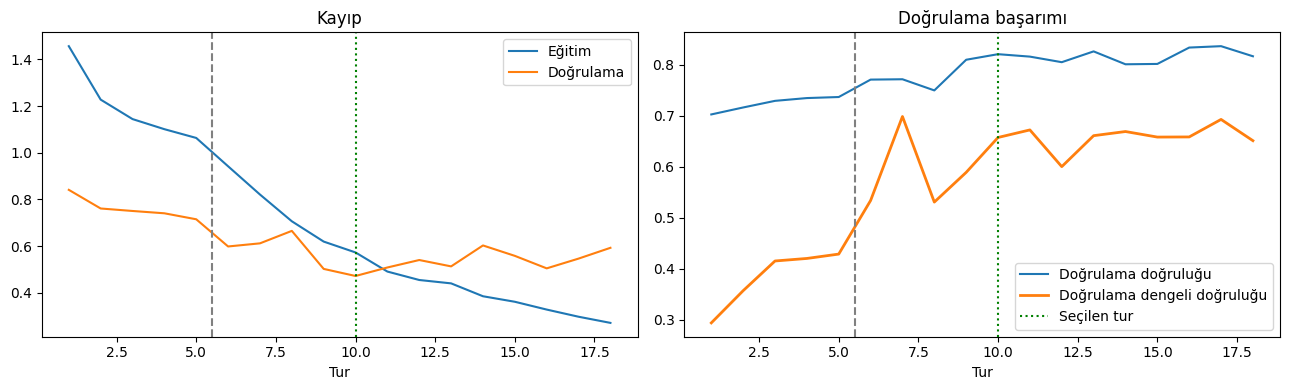

In [9]:
h = {k: gecmis1.history[k] + gecmis2.history.get(k, []) for k in gecmis1.history}
turlar = np.arange(1, len(h['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(turlar, h['loss'], label='Eğitim'); ax[0].plot(turlar, h['val_loss'], label='Doğrulama')
ax[0].set_title('Kayıp'); ax[0].set_xlabel('Tur'); ax[0].legend()
ax[1].plot(turlar, h['val_accuracy'], label='Doğrulama doğruluğu')
ax[1].plot(turlar, kayit.gecmis, label='Doğrulama dengeli doğruluğu', linewidth=2)
ax[1].set_title('Doğrulama başarımı'); ax[1].set_xlabel('Tur'); ax[1].legend()
for a in ax: a.axvline(EPOCH_BAS + 0.5, color='gray', linestyle='--')
for a in ax: a.axvline(kayit.en_iyi_tur, color='green', linestyle=':', label='Seçilen tur')
ax[1].legend()
plt.tight_layout(); plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_egitim_egrisi.png', dpi=150); plt.show()
pd.DataFrame({**h, 'val_bal_acc': kayit.gecmis}).to_csv(f'{PROJE}/results/02_{MODEL_ADI}_egitim_gecmisi.csv', index_label='tur')

## 10. En iyi modeli doğrulama kümesinde değerlendir (TTA ile ve TTA'sız)
Kaydedilen en iyi model yüklenir ve doğrulama kümesi iki şekilde tahmin edilir:
- **Tek geçiş:** Görüntü olduğu gibi.
- **TTA (test anında çoğaltma):** Görüntü 8 farklı yönde (0°, 90°, 180°, 270° döndürme ve aynalamalar) tahmin edilir; logitler ortalanır. Lezyonun yönü tanıyı değiştirmediği için bu, tahmini daha kararlı yapar.

**Kural (önceden yazıldı):** TTA, doğrulama kaybını (NLL) düşürürse kullanılır. Test kümesine hâlâ dokunulmaz.

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score

def softmax_np(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def tta_logit(model, ds):
    donusumler = [lambda x: x,
                  lambda x: tf.image.rot90(x, 1), lambda x: tf.image.rot90(x, 2), lambda x: tf.image.rot90(x, 3),
                  lambda x: tf.image.flip_left_right(x), lambda x: tf.image.flip_up_down(x),
                  lambda x: tf.image.flip_left_right(tf.image.rot90(x, 1)),
                  lambda x: tf.image.flip_up_down(tf.image.rot90(x, 1))]
    def uygula(d):
        return lambda x, y: d(x)
    return np.mean([model.predict(ds.map(uygula(d)), verbose=0) for d in donusumler], axis=0)

def degerlendir(logit, y):
    p = softmax_np(logit.astype('float64')); tahmin = p.argmax(1)
    r = classification_report(y, tahmin, labels=range(len(SINIFLAR)), target_names=[SINIF_ADI[s] for s in SINIFLAR],
                              output_dict=True, zero_division=0)
    return {'dengeli_dogruluk': float(balanced_accuracy_score(y, tahmin)),
            'dogruluk': float((tahmin == y).mean()),
            'makro_f1': float(f1_score(y, tahmin, average='macro')),
            'makro_auc': float(roc_auc_score(y, p, multi_class='ovr', average='macro')),
            'melanom_duyarliligi': float(r['Melanom']['recall']),
            'dogrulama_nll': float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())}

en_iyi_model = keras.models.load_model(MODEL_YOLU)
t0 = time.time()
logit_tek = en_iyi_model.predict(dogrulama_ds, verbose=0).astype('float64')
logit_tta = tta_logit(en_iyi_model, dogrulama_ds).astype('float64')
print(f'Tahmin süresi: {(time.time() - t0) / 60:.1f} dk')
m_tek, m_tta = degerlendir(logit_tek, y_dogrulama), degerlendir(logit_tta, y_dogrulama)
TTA_KULLAN = m_tta['dogrulama_nll'] < m_tek['dogrulama_nll']
print(pd.DataFrame({'tek_gecis': m_tek, 'TTA': m_tta}).round(4).to_string())
print(f'\nKural sonucu: TTA {"KULLANILACAK" if TTA_KULLAN else "kullanılmayacak"} (doğrulama NLL\'ye göre)')

logit_dog = logit_tta if TTA_KULLAN else logit_tek
metrikler = dict(m_tta if TTA_KULLAN else m_tek)
olasilik_dog = softmax_np(logit_dog)
tahmin_dog = olasilik_dog.argmax(1)
rapor = classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                              target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3,
                              output_dict=True, zero_division=0)
print()
print(classification_report(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)),
                            target_names=[SINIF_ADI[s] for s in SINIFLAR], digits=3, zero_division=0))

Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b9422a2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b9422a2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b94229ee0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b94229ee0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b95a6fe20>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0b95a6fe20>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.rot90(x, 1)

Match 1:
lambda x: tf.image.rot90(x, 2)

Match 2:
lambda x: tf.image.rot90(x, 3)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0bcfada2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.flip_left_right(x)

Match 1:
lambda x: tf.image.flip_up_down(x)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0bcfada2a0>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.flip_left_right(x)

Match 1:
lambda x: tf.image.flip_up_down(x)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0bcfada340>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.flip_left_right(x)

Match 1:
lambda x: tf.image.flip_up_down(x)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: could not parse the source code of <function tta_logit.<locals>.<lambda> at 0x7a0bcfada340>: found multiple definitions with identical signatures at the location. This error may be avoided by defining each lambda on a single line and with unique argument names. The matching definitions were:
Match 0:
lambda x: tf.image.flip_left_right(x)

Match 1:
lambda x: tf.image.flip_up_down(x)

To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Tahmin süresi: 0.9 dk
                     tek_gecis     TTA
dengeli_dogruluk        0.6577  0.6717
dogruluk                0.8210  0.8313
makro_f1                0.6711  0.6890
makro_auc               0.9641  0.9672
melanom_duyarliligi     0.3155  0.3690
dogrulama_nll           0.4724  0.4513

Kural sonucu: TTA KULLANILACAK (doğrulama NLL'ye göre)

                         precision    recall  f1-score   support

        Aktinik keratoz      0.793     0.535     0.639        43
 Bazal hücreli karsinom      0

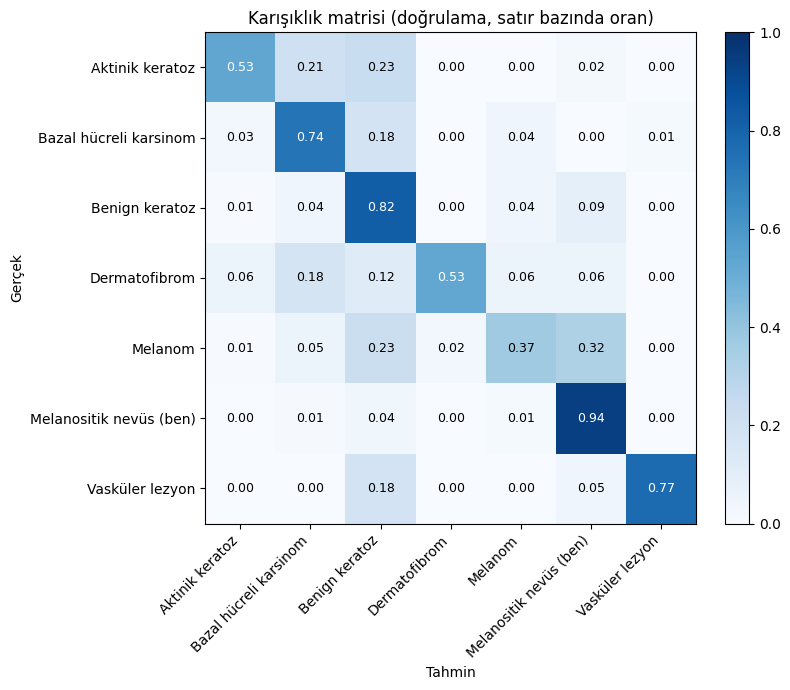

In [11]:
km = confusion_matrix(y_dogrulama, tahmin_dog, labels=range(len(SINIFLAR)), normalize='true')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(km, cmap='Blues', vmin=0, vmax=1)
etiket = [SINIF_ADI[s] for s in SINIFLAR]
ax.set_xticks(range(len(etiket)), etiket, rotation=45, ha='right'); ax.set_yticks(range(len(etiket)), etiket)
for i in range(len(etiket)):
    for j in range(len(etiket)):
        ax.text(j, i, f'{km[i, j]:.2f}', ha='center', va='center', color='white' if km[i, j] > 0.5 else 'black', fontsize=9)
ax.set_xlabel('Tahmin'); ax.set_ylabel('Gerçek'); ax.set_title('Karışıklık matrisi (doğrulama, satır bazında oran)')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_karisiklik_matrisi.png', dpi=150); plt.show()

## 10b. Karar ayarı (logit ayarı): iki seçim kuralı
ayarlı skor = logit − τ × log(o sınıfın eğitimdeki oranı). τ büyüdükçe "ben" yönündeki eğilim azalır; melanom duyarlılığı artar, nevüs duyarlılığı düşer.

İki τ raporlanır (ikisi de yalnızca doğrulamada seçilir):
- **τ (dengeli):** Dengeli doğruluğu en yükselten. v3'te 1,05 çıktı ve testte nevüslerin %38'ine yanlış alarm verdi.
- **τ (klinik):** Nevüs duyarlılığı en az 0,80 kalacak şekilde dengeli doğruluğu en yükselten. Gereksiz biyopsiyi sınırlar; klinik olarak daha savunulabilir.

Aşağıdaki grafik, τ'ya göre melanom ve nevüs duyarlılığının nasıl değiştiğini (ödünleşimi) gösterir.

τ (dengeli) = 1.3 | τ (klinik, nevüs duyarlılığı ≥ 0.8) = 0.75

                     ayarsiz (τ=0)  dengeli (τ=1.3)  klinik (τ=0.75)
dengeli_dogruluk             0.672            0.733            0.710
dogruluk                     0.831            0.644            0.764
makro_f1                     0.689            0.544            0.617
melanom_duyarliligi          0.369            0.512            0.488
nevus_duyarliligi            0.939            0.637            0.815


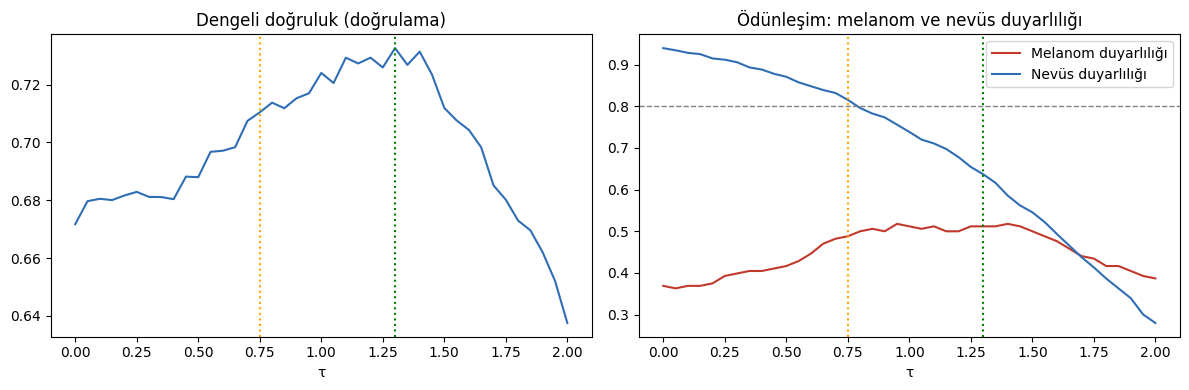

In [12]:
oncel = np.bincount(egitim['y'], minlength=len(SINIFLAR)) / len(egitim)
log_oncel = np.log(oncel)
MEL, NV = SINIFLAR.index('mel'), SINIFLAR.index('nv')
taular = np.round(np.arange(0, 2.0001, 0.05), 2)
egri = []
for t in taular:
    tah = (logit_dog - t * log_oncel).argmax(1)
    egri.append({'tau': t, 'dengeli': balanced_accuracy_score(y_dogrulama, tah),
                 'melanom_duy': (tah[y_dogrulama == MEL] == MEL).mean(),
                 'nevus_duy': (tah[y_dogrulama == NV] == NV).mean()})
egri = pd.DataFrame(egri)
TAU = float(egri.loc[egri['dengeli'].idxmax(), 'tau'])
uygun = egri[egri['nevus_duy'] >= NEVUS_ALT_SINIR]
TAU_KLINIK = float(uygun.loc[uygun['dengeli'].idxmax(), 'tau']) if len(uygun) else 0.0

def ayarli_olc(t):
    tah = (logit_dog - t * log_oncel).argmax(1)
    r = classification_report(y_dogrulama, tah, labels=range(len(SINIFLAR)), target_names=[SINIF_ADI[s] for s in SINIFLAR],
                              output_dict=True, zero_division=0)
    return {'dengeli_dogruluk': balanced_accuracy_score(y_dogrulama, tah), 'dogruluk': (tah == y_dogrulama).mean(),
            'makro_f1': f1_score(y_dogrulama, tah, average='macro'),
            'melanom_duyarliligi': r['Melanom']['recall'], 'nevus_duyarliligi': r['Melanositik nevüs (ben)']['recall']}, r

o_ayarsiz, _ = ayarli_olc(0.0)
o_dengeli, rapor_ayarli = ayarli_olc(TAU)
o_klinik, _ = ayarli_olc(TAU_KLINIK)
metrikler['tau'] = TAU
metrikler['ayarli_dengeli_dogruluk'] = float(o_dengeli['dengeli_dogruluk'])
metrikler['ayarli_dogruluk'] = float(o_dengeli['dogruluk'])
metrikler['ayarli_makro_f1'] = float(o_dengeli['makro_f1'])
metrikler['ayarli_melanom_duyarliligi'] = float(o_dengeli['melanom_duyarliligi'])
metrikler['tau_klinik'] = TAU_KLINIK
metrikler['klinik_dengeli_dogruluk'] = float(o_klinik['dengeli_dogruluk'])
metrikler['klinik_melanom_duyarliligi'] = float(o_klinik['melanom_duyarliligi'])
metrikler['klinik_nevus_duyarliligi'] = float(o_klinik['nevus_duyarliligi'])

print(f'τ (dengeli) = {TAU} | τ (klinik, nevüs duyarlılığı ≥ {NEVUS_ALT_SINIR}) = {TAU_KLINIK}\n')
print(pd.DataFrame({'ayarsiz (τ=0)': o_ayarsiz, f'dengeli (τ={TAU})': o_dengeli, f'klinik (τ={TAU_KLINIK})': o_klinik}).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(egri['tau'], egri['dengeli'], color='#2F6DB5'); ax[0].set_title('Dengeli doğruluk (doğrulama)')
ax[1].plot(egri['tau'], egri['melanom_duy'], label='Melanom duyarlılığı', color='#C0392B')
ax[1].plot(egri['tau'], egri['nevus_duy'], label='Nevüs duyarlılığı', color='#2F6DB5')
ax[1].axhline(NEVUS_ALT_SINIR, color='gray', linestyle='--', linewidth=1)
ax[1].set_title('Ödünleşim: melanom ve nevüs duyarlılığı'); ax[1].legend()
for a in ax:
    a.axvline(TAU, color='green', linestyle=':', label='τ dengeli'); a.axvline(TAU_KLINIK, color='orange', linestyle=':', label='τ klinik')
    a.set_xlabel('τ')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/02_{MODEL_ADI}_logit_ayari.png', dpi=150); plt.show()

## 11. Sonuçları kaydet
Seçilen logitler (TTA kuralına göre) Adım 3 için kaydedilir; tek geçiş ve TTA logitleri ayrıca saklanır.

In [13]:
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit.npy', logit_dog)
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit_tek.npy', logit_tek)
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_logit_tta.npy', logit_tta)
np.save(f'{PROJE}/models/{MODEL_ADI}_dogrulama_y.npy', y_dogrulama)
pd.DataFrame(rapor).T.to_csv(f'{PROJE}/results/02_{MODEL_ADI}_siniflandirma_raporu.csv')
with open(f'{PROJE}/results/02_{MODEL_ADI}_dogrulama_metrikleri.json', 'w', encoding='utf-8') as f:
    json.dump({'model': MODEL_ADI, 'img': IMG, 'siniflar': SINIFLAR, **metrikler,
               'tta_kullan': bool(TTA_KULLAN), 'tek': m_tek, 'tta': m_tta, 'cam_katmani': CAM_KATMANI,
               'onisleme': 'yuvarla_uint8', 'nevus_alt_siniri': NEVUS_ALT_SINIR,
               'ayarlar': {'model_tipi': MODEL_TIPI, 'agirlik_tipi': AGIRLIK_TIPI, 'secim_olcutu': SECIM_OLCUTU,
                           'agirlik_azalma': AGIRLIK_AZALMA, 'secilen_tur': kayit.en_iyi_tur, 'batch': BATCH, 'epoch_bas': EPOCH_BAS, 'epoch_ince': EPOCH_INCE,
                           'lr_bas': LR_BAS, 'lr_ince': LR_INCE, 'lr_plani': 'kosinus_isinmali', 'acilan_katman': ACILACAK,
                           'tur_sayisi': len(kayit.gecmis)}},
              f, ensure_ascii=False, indent=2)
print('Kaydedildi:')
for p in [f'models/{MODEL_ADI}.keras', f'models/{MODEL_ADI}_dogrulama_logit.npy',
          f'results/02_{MODEL_ADI}_egitim_egrisi.png', f'results/02_{MODEL_ADI}_karisiklik_matrisi.png',
          f'results/02_{MODEL_ADI}_siniflandirma_raporu.csv', f'results/02_{MODEL_ADI}_dogrulama_metrikleri.json',
          f'results/02_{MODEL_ADI}_egitim_gecmisi.csv', f'results/02_{MODEL_ADI}_logit_ayari.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  models/cnn_b0_v4.keras ✓
  models/cnn_b0_v4_dogrulama_logit.npy ✓
  results/02_cnn_b0_v4_egitim_egrisi.png ✓
  results/02_cnn_b0_v4_karisiklik_matrisi.png ✓
  results/02_cnn_b0_v4_siniflandirma_raporu.csv ✓
  results/02_cnn_b0_v4_dogrulama_metrikleri.json ✓
  results/02_cnn_b0_v4_egitim_gecmisi.csv ✓
  results/02_cnn_b0_v4_logit_ayari.png ✓


## 12. Önceki denemelerle karşılaştır ve modeli seç
Drive'daki bütün Adım 2 sonuçları tek tabloda gösterilir. v4 için tek geçiş ve TTA ayrı satırlardır.

**Seçim kuralı (önceden yazıldı):** En yüksek ayarsız dengeli doğruluk; fark 0,01'den küçükse doğrulama kaybı (NLL) düşük olan. Seçim `results/02_secilen_model.json` dosyasına yazılır ve Adım 3 bu dosyayı okuyacak.

In [14]:
def nll_dosyadan(model_adi):
    l, yy = f'{PROJE}/models/{model_adi}_dogrulama_logit.npy', f'{PROJE}/models/{model_adi}_dogrulama_y.npy'
    if not (os.path.exists(l) and os.path.exists(yy)):
        return np.nan
    z, y = np.load(l).astype('float64'), np.load(yy)
    p = softmax_np(z)
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

satirlar = []
for yol in sorted(glob.glob(f'{PROJE}/results/02*dogrulama_metrikleri.json')):
    with open(yol, encoding='utf-8') as f:
        m = json.load(f)
    ad = m['model'] + (' (v1)' if os.path.basename(yol) == '02_dogrulama_metrikleri.json' else '')
    if 'tek' in m and 'tta' in m:
        for etiket, alt, tta in [('', m['tek'], False), (' + TTA', m['tta'], True)]:
            satirlar.append({'model': m['model'] + etiket, 'model_dosyasi': m['model'], 'tta': tta,
                             'dengeli_dogruluk': alt['dengeli_dogruluk'], 'dogruluk': alt['dogruluk'],
                             'makro_f1': alt['makro_f1'], 'makro_auc': alt['makro_auc'],
                             'melanom_duyarliligi': alt['melanom_duyarliligi'], 'dogrulama_nll': alt['dogrulama_nll']})
    else:
        satirlar.append({'model': ad, 'model_dosyasi': m['model'], 'tta': False,
                         'dengeli_dogruluk': m['dengeli_dogruluk'], 'dogruluk': m['dogruluk'],
                         'makro_f1': m['makro_f1'], 'makro_auc': m['makro_auc'],
                         'melanom_duyarliligi': m['melanom_duyarliligi'], 'dogrulama_nll': nll_dosyadan(m['model'])})
tablo = pd.DataFrame(satirlar)
print(tablo.drop(columns=['model_dosyasi']).round(3).to_string(index=False))

en_iyi = tablo['dengeli_dogruluk'].max()
yakin = tablo[tablo['dengeli_dogruluk'] >= en_iyi - 0.01].sort_values('dogrulama_nll', na_position='last')
secilen = yakin.iloc[0]
with open(f'{PROJE}/results/02_secilen_model.json', 'w', encoding='utf-8') as f:
    json.dump({'model': secilen['model_dosyasi'], 'tta': bool(secilen['tta']),
               'dengeli_dogruluk': float(secilen['dengeli_dogruluk']), 'dogrulama_nll': float(secilen['dogrulama_nll']),
               'kural': 'en yüksek doğrulama dengeli doğruluğu; 0,01 içinde ise en düşük doğrulama NLL'},
              f, ensure_ascii=False, indent=2)
print(f'\nDOĞRULAMAYA GÖRE SEÇİLEN: {secilen["model"]} (dengeli doğruluk {secilen["dengeli_dogruluk"]:.3f}, NLL {secilen["dogrulama_nll"]:.4f})')
print('Kaydedildi: results/02_secilen_model.json')

          model   tta  dengeli_dogruluk  dogruluk  makro_f1  makro_auc  melanom_duyarliligi  dogrulama_nll
      cnn_b0_v2 False             0.673     0.766     0.602      0.952                0.446          0.606
      cnn_b0_v3 False             0.695     0.842     0.713      0.968                0.530          0.460
      cnn_b0_v4 False             0.658     0.821     0.671      0.964                0.315          0.472
cnn_b0_v4 + TTA  True             0.672     0.831     0.689      0.967                0.369          0.451
      cnn_b3_v3 False             0.696     0.832     0.717      0.970                0.750          0.514
    cnn_b0 (v1) False             0.653     0.642     0.487      0.929                0.583          0.889

DOĞRULAMAYA GÖRE SEÇİLEN: cnn_b0_v3 (dengeli doğruluk 0.695, NLL 0.4602)
Kaydedildi: results/02_secilen_model.json


## Bu adımın sonunda
- v4 modeli Drive'da: `bitirme/models/cnn_b0_v4.keras` (v3 silinmedi).
- Doğrulamaya göre seçilen model `results/02_secilen_model.json` dosyasında.
- **Bana gönder:** defteri *Dosya → İndir → .ipynb* ile indirip gönder. Sonra Adım 3'ü seçilen modelle (ve karşılaştırma için v3 ile) yeniden çalıştıracağız.